In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import LabelEncoder

In [4]:
def man_dist(x,y):
    dim = x.shape[0]
    dist_val = 0 # dist의 최소값은 0, 최대값은 무한대
    for i in range(0,dim):
        dist_val += np.abs(x[i]-y[i])


    return dist_val;

## 데이터셋

toy example

In [3]:
X = np.array([[0,0],
              [3,9],
              [1,2],
              [11,7]])

num, dim = X.shape

Y = ['x1','x2', 'x3','x4']

print(X,Y)   
print(num,dim)

[[ 0  0]
 [ 3  9]
 [ 1  2]
 [11  7]] ['x1', 'x2', 'x3', 'x4']
4 2


iris

In [ ]:
df = pd.read_csv("datasets/iris.data", header=None) # 다른 데이터셋으로 해보면 가산점 (재밌는 데이터)
# print(df.head())
df = df.to_numpy()
X = df[:,0:-1]
Y = df[:,-1]
num, dim = X.shape

# print(X)
# print(Y)
print(num,dim)

150 4


## Proximity matrix

In [7]:
mat = np.zeros((num,num))

for i in range(num):
    for j in range(num):
        if i != j:
            mat[i,j] = man_dist(X[i,:], X[j,:])
        else:
            mat[i,j] = 1000

print(mat)

[[1000.   12.    3.   18.]
 [  12. 1000.    9.   10.]
 [   3.    9. 1000.   15.]
 [  18.   10.   15. 1000.]]


In [ ]:
# toy example

# single
linked_sin = linkage(X, method = "single", metric = "cityblock")

plt.figure(figsize=(7,4))
dendrogram(linked_sin, labels = Y)

# complete
linked_com = linkage(X, method = "complete", metric = "cityblock")

plt.figure(figsize=(7,4))
dendrogram(linked_com, labels= Y)

# average
linked_avg = linkage(X, method = "average", metric= "cityblock")

plt.figure(figsize=(7,4))
dendrogram(linked_avg, labels = Y)

# centroid
linked_cen = linkage(X, method = "centroid", metric= "euclidean")

plt.figure(figsize=(7,4))
dendrogram(linked_cen, labels = Y)

{'icoord': [[25.0, 25.0, 35.0, 35.0],
  [15.0, 15.0, 30.0, 30.0],
  [5.0, 5.0, 22.5, 22.5],
  [55.0, 55.0, 65.0, 65.0],
  [45.0, 45.0, 60.0, 60.0],
  [13.75, 13.75, 52.5, 52.5],
  [85.0, 85.0, 95.0, 95.0],
  [75.0, 75.0, 90.0, 90.0],
  [105.0, 105.0, 115.0, 115.0],
  [125.0, 125.0, 135.0, 135.0],
  [110.0, 110.0, 130.0, 130.0],
  [82.5, 82.5, 120.0, 120.0],
  [155.0, 155.0, 165.0, 165.0],
  [175.0, 175.0, 185.0, 185.0],
  [160.0, 160.0, 180.0, 180.0],
  [145.0, 145.0, 170.0, 170.0],
  [205.0, 205.0, 215.0, 215.0],
  [195.0, 195.0, 210.0, 210.0],
  [157.5, 157.5, 202.5, 202.5],
  [101.25, 101.25, 180.0, 180.0],
  [225.0, 225.0, 235.0, 235.0],
  [255.0, 255.0, 265.0, 265.0],
  [245.0, 245.0, 260.0, 260.0],
  [230.0, 230.0, 252.5, 252.5],
  [295.0, 295.0, 305.0, 305.0],
  [285.0, 285.0, 300.0, 300.0],
  [325.0, 325.0, 335.0, 335.0],
  [315.0, 315.0, 330.0, 330.0],
  [292.5, 292.5, 322.5, 322.5],
  [275.0, 275.0, 307.5, 307.5],
  [241.25, 241.25, 291.25, 291.25],
  [140.625, 140.625, 266.2

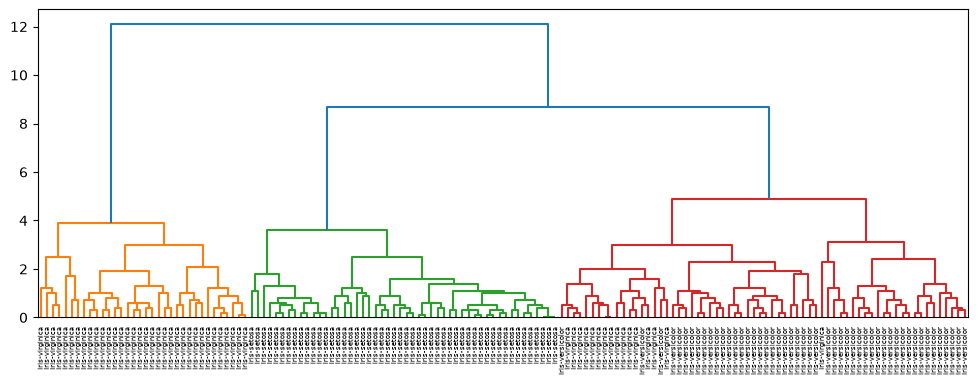

In [ ]:
# iris data

# single
linked_sin = linkage(X, method = "single", metric = "cityblock") # unsupervised running

plt.figure(figsize=(12,4))
dendrogram(linked_sin, labels = Y)

# complete
linked_com = linkage(X, method = "complete", metric = "cityblock")

plt.figure(figsize=(12,4))
dendrogram(linked_com, labels= Y)

# average
linked_avg = linkage(X, method = "average", metric= "cityblock")

plt.figure(figsize=(12,4))
dendrogram(linked_avg, labels = Y)

# centroid
linked_cen = linkage(X, method = "centroid", metric= "euclidean")

plt.figure(figsize=(12,4))
dendrogram(linked_cen, labels = Y)

In [ ]:
group = fcluster(linked_com, t=3, criterion="maxclust")
# group = fcluster(linked_com, t=3.5, criterion="distance")

print(group)

[4 3 3 3 4 4 3 4 3 4 4 4 3 3 4 4 4 4 4 4 4 4 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 3 4 4 3 3 4 4 3 4 3 4 4 5 5 5 6 5 6 5 6 5 6 6 5 6 5 6 5 6 6 5 6 5 5 5 5
 5 5 5 5 5 6 6 6 6 5 6 5 5 5 6 6 6 5 6 6 6 5 5 5 6 6 2 5 2 2 2 1 6 2 2 1 2
 5 2 5 5 2 2 1 1 5 2 5 1 5 2 2 5 5 2 2 2 1 2 5 5 1 2 2 5 2 2 2 5 2 2 2 5 2
 2 5]
